# Mini Assignment Data Sains dan AI
## Klasifikasi Breast Cancer: Logistic Regression vs Random Forest

Dataset: Breast Cancer Wisconsin (Scikit-learn). Pembagian data 70% training dan 30% testing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


## 1. Memuat dan Eksplorasi Dataset

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("\nTarget Classes:", data.target_names)
print("\nMissing Values:", X.isnull().sum().sum())
X.head()

Dataset Shape: (569, 30)

Target Classes: ['malignant' 'benign']

Missing Values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Class Distribution:
0    212
1    357
Name: count, dtype: int64


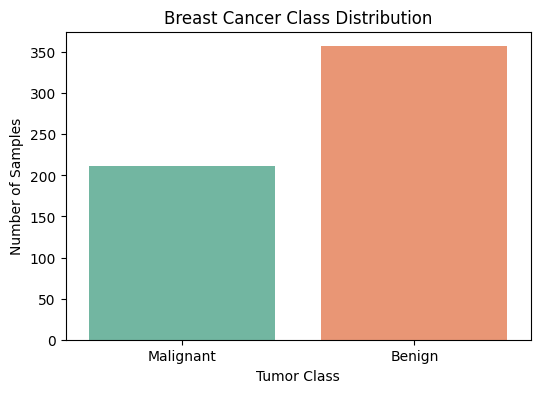

In [3]:
class_counts = pd.Series(y).value_counts().sort_index()
print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, palette="Set2", legend=False)
plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.show()

## 2. Pembagian Dataset (70% Training, 30% Testing)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 398
Testing Samples: 171


## 3. Pelatihan Model

In [5]:
# Logistic Regression (dengan standardisasi fitur)
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("Training kedua model selesai!")

Training kedua model selesai!


## 4. Evaluasi: Accuracy, Precision, Recall, F1-score

In [6]:
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9883,0.9907,0.9907,0.9907
Random Forest,0.9357,0.9444,0.9533,0.9488


In [7]:
for name, y_pred in predictions.items():
    print("=" * 50)
    print(name)
    print(classification_report(y_test, y_pred, target_names=data.target_names))

Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

Random Forest
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



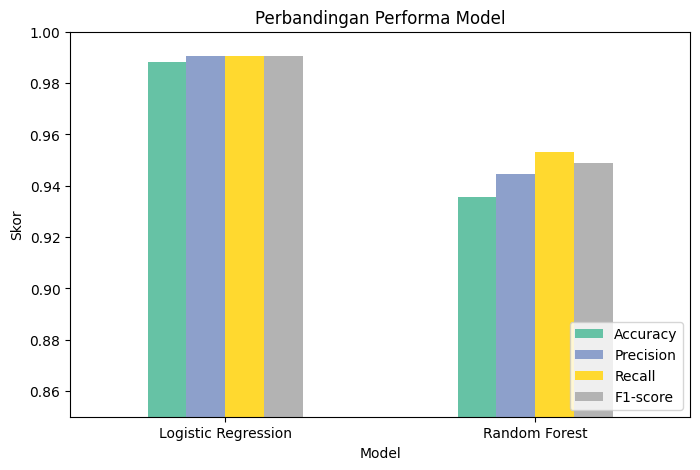

In [8]:
# Visualisasi perbandingan metrik
results_df.plot(kind="bar", figsize=(8, 5), colormap="Set2")
plt.title("Perbandingan Performa Model")
plt.ylabel("Skor")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 5. Confusion Matrix

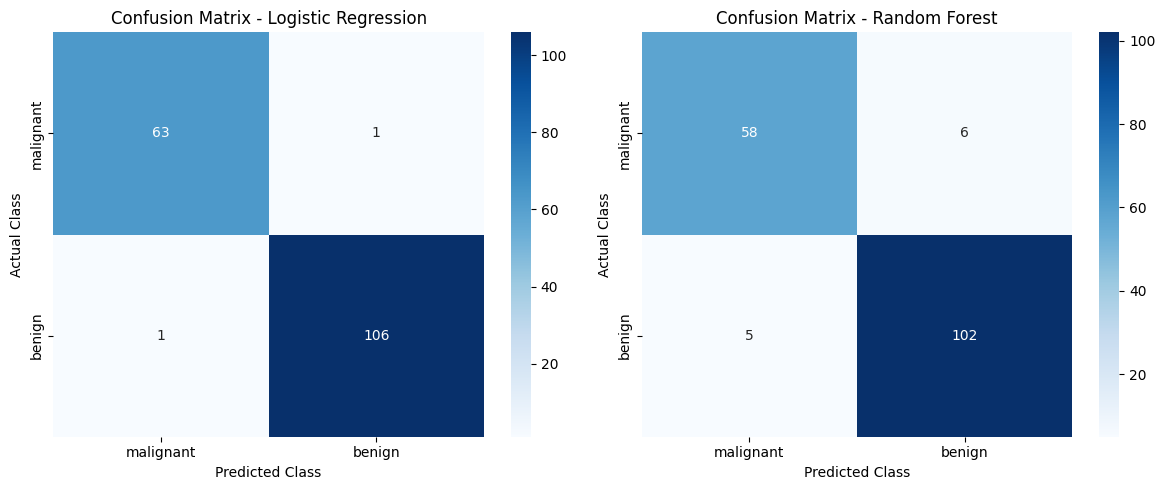

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 6. Fitur Terpenting (Random Forest)

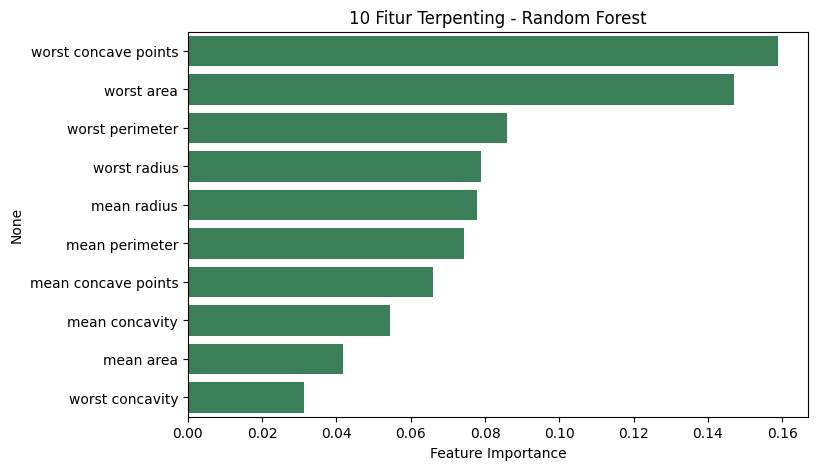

In [10]:
importances = pd.Series(
    rf.feature_importances_, index=data.feature_names
).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, color="seagreen")
plt.title("10 Fitur Terpenting - Random Forest")
plt.xlabel("Feature Importance")
plt.show()

## 7. Analisis Hasil Eksperimen

**Hasil metrik pada data testing (171 sampel: 64 malignant, 107 benign):**

| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression | 0.9883 | 0.9907 | 0.9907 | 0.9907 |
| Random Forest | 0.9357 | 0.9444 | 0.9533 | 0.9488 |

**Confusion matrix:**
- **Logistic Regression**: 63 malignant dan 106 benign diprediksi benar. Hanya ada 2 kesalahan (1 malignant diprediksi benign, 1 benign diprediksi malignant).
- **Random Forest**: 58 malignant dan 102 benign diprediksi benar. Ada 11 kesalahan (6 malignant diprediksi benign, 5 benign diprediksi malignant).

**Pembahasan:**
1. Logistic Regression unggul pada seluruh metrik. Selisih accuracy sekitar 5 poin persentase dan selisih F1-score sekitar 4 poin.
2. Hal ini wajar karena fitur pada dataset ini bersifat numerik, saling berkorelasi kuat, dan kelas-kelasnya hampir terpisah secara linear, sehingga model linear dengan standardisasi fitur sudah sangat cocok. Random Forest, yang bersifat non-linear, tidak memberi keuntungan tambahan dan dengan data training hanya 398 sampel lebih rentan terhadap variasi.
3. Dalam konteks diagnosis kanker, kesalahan yang paling berbahaya adalah *false negative* (tumor malignant diprediksi benign) karena pasien tidak mendapat penanganan. Logistic Regression hanya menghasilkan 1 false negative, sedangkan Random Forest menghasilkan 6.
4. Random Forest memberi informasi tambahan berupa feature importance. Fitur paling berpengaruh adalah *worst concave points*, *worst area*, dan *worst perimeter*, yaitu ukuran dan kecembungan sel tumor yang memang berkaitan dengan keganasan.
5. Hasil ini berasal dari satu kali pembagian data (random_state=42), sehingga selisih performa bisa sedikit berubah pada pembagian yang berbeda. Cross-validation dapat dipakai untuk hasil yang lebih stabil.

## 8. Kesimpulan

Pada eksperimen klasifikasi Breast Cancer dengan pembagian data 70:30, **Logistic Regression menunjukkan performa terbaik** (accuracy 98,83% dan F1-score 0,9907) dibandingkan Random Forest (accuracy 93,57% dan F1-score 0,9488). Logistic Regression juga menghasilkan *false negative* paling sedikit (1 dibanding 6), yang penting dalam deteksi kanker. Untuk dataset ini, model yang lebih sederhana dan mudah diinterpretasi terbukti lebih efektif daripada model ensemble yang lebih kompleks.